In [62]:
!pip install datasets transformers sentence-transformers gradio scikit-learn scikit-image matplotlib torch torchmetrics torch-fidelity kagglehub -q

In [63]:
import os, glob, json, zipfile, shutil
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [64]:
from google.colab import drive
drive.mount('/content/drive')

D = "/content/drive/MyDrive/cognitive_mirror"
os.makedirs(D, exist_ok=True)
print("Saving to:", D)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving to: /content/drive/MyDrive/cognitive_mirror


In [65]:
from google.colab import drive
drive.mount('/content/drive')

D = "/content/drive/MyDrive/cognitive_mirror"
os.makedirs(D, exist_ok=True)
print("Saving to:", D)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving to: /content/drive/MyDrive/cognitive_mirror


In [66]:
from google.colab import files
uploaded = files.upload()

Saving Go emotions.zip to Go emotions.zip


In [67]:
zip_name = list(uploaded.keys())[0]
zf = zipfile.ZipFile(zip_name, 'r')
zf.extractall("go_emotions_extracted")
zf.close()

df = pd.read_csv("go_emotions_extracted/go_emotions_dataset.csv")
print(df.shape)
df.head()

(211225, 31)


,id,text,example_very_unclear,admiration,amusement,anger,annoyance,approval,caring,confusion,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,eew5j0j,That game hurt.,False,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,eemcysk,>sexuality shouldn’t be a grouping category I...,True,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,ed2mah1,"You do right, if you don't care then fuck 'em!",False,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3,eeibobj,Man I love reddit.,False,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,eda6yn6,"[NAME] was nowhere near them, he was by the Fa...",False,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [68]:
print(list(uploaded.keys()))

['Go emotions.zip']


In [69]:
label_names = df.columns[3:].tolist()
num_labels = len(label_names)
print(num_labels, label_names)

28 ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']


In [70]:
uploaded_fer = files.upload()
print(list(uploaded_fer.keys()))

Saving fer2013.zip to fer2013.zip
['fer2013.zip']


In [71]:
fer_name = list(uploaded_fer.keys())[0]
fer_df = pd.read_csv(fer_name)
print(fer_df.shape)
fer_df.head()

(35887, 3)


,emotion,pixels,Usage
0,0,70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...,Training
1,0,151 150 147 155 148 133 111 140 170 174 182 15...,Training
2,2,231 212 156 164 174 138 161 173 182 200 106 38...,Training
3,4,24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...,Training
4,6,4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...,Training


In [72]:
#Take a subset and convert the pixels into images
fer_df = fer_df.sample(6000, random_state=42).reset_index(drop=True)

face_emotions = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]

def to_image(pixel_string):
    return np.array(pixel_string.split(), dtype=np.float32) / 255.0

fer_images = np.stack(fer_df["pixels"].apply(to_image).values)
fer_labels = fer_df["emotion"].values

print(fer_images.shape)

(6000, 2304)


In [73]:
import kagglehub

path = kagglehub.dataset_download("jessicali9530/celeba-dataset")
img_files = sorted(glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True))
print(len(img_files), "images found")

Using Colab cache for faster access to the 'celeba-dataset' dataset.
202599 images found


In [74]:
import os, json, math, copy, glob, zipfile, shutil, time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [75]:
for name in ["img_files", "N_CELEB", "pick", "fer_images", "fer_labels", "face_emotions", "D"]:
    print(name, "OK" if name in globals() else "MISSING")

img_files OK
N_CELEB MISSING
pick MISSING
fer_images OK
fer_labels OK
face_emotions OK
D OK


In [76]:
#Take a subset, crop the face, shrink to 48x48 grayscale
N_CELEB = 20000     # use 10000 if training is too slow
pick = np.random.default_rng(42).choice(len(img_files), N_CELEB, replace=False)

def load_face(p):
    im = Image.open(p).convert("L")
    im = im.crop((15, 40, 163, 188))
    im = im.resize((48, 48), Image.LANCZOS)
    return np.asarray(im, dtype=np.float32) / 255.0

celeb_images = np.stack([load_face(img_files[i]) for i in pick]).reshape(N_CELEB, 2304)

#Smiling label (1 = smiling, 0 = not smiling)
attr_file = glob.glob(os.path.join(path, "**", "list_attr_celeba.csv"), recursive=True)[0]
attr = pd.read_csv(attr_file).set_index("image_id")
names = [os.path.basename(img_files[i]) for i in pick]
celeb_smile = (attr.loc[names, "Smiling"].values == 1).astype(int)

print(celeb_images.shape)

(20000, 2304)


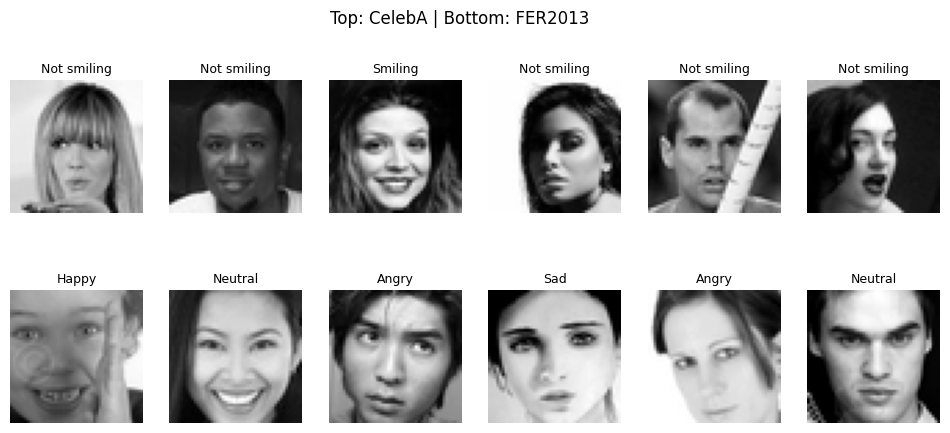

In [77]:
#look at the faces
fig, axes = plt.subplots(2, 6, figsize=(12, 5))
for i in range(6):
    axes[0][i].imshow(celeb_images[i].reshape(48, 48), cmap="gray")
    axes[0][i].set_title("Smiling" if celeb_smile[i] else "Not smiling", fontsize=9)
    axes[0][i].axis("off")
    axes[1][i].imshow(fer_images[i].reshape(48, 48), cmap="gray")
    axes[1][i].set_title(face_emotions[fer_labels[i]], fontsize=9)
    axes[1][i].axis("off")
axes[0][0].set_ylabel("CelebA")
plt.suptitle("Top: CelebA | Bottom: FER2013")
plt.show()

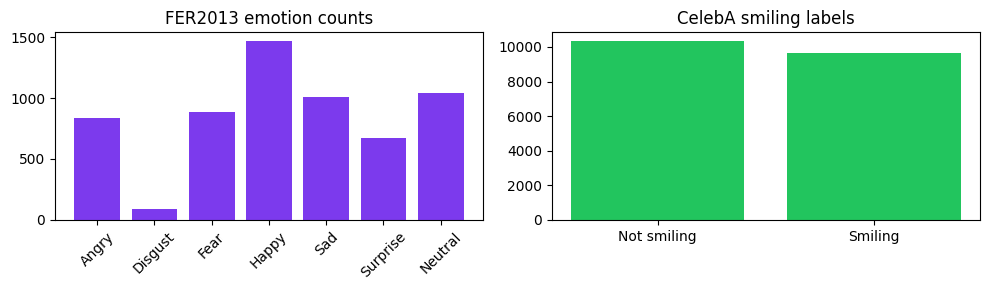

In [101]:
#label counts (new chart)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].bar(face_emotions, np.bincount(fer_labels, minlength=7), color="#7c3aed")
ax[0].set_title("FER2013 emotion counts")
ax[0].tick_params(axis="x", rotation=45)
ax[1].bar(["Not smiling", "Smiling"], np.bincount(celeb_smile), color="#22c55e")
ax[1].set_title("CelebA smiling labels")
plt.tight_layout()
plt.show()

In [102]:
#The AE, VAE, GAN and Diffusion train on CelebA
images = celeb_images
img_labels = celeb_smile

split = N_CELEB - 2000
X_train_img = torch.tensor(images[:split]).to(device)
X_val_img = torch.tensor(images[split:]).to(device)

#FER is kept for the face emotion classifier
X_fer = torch.tensor(fer_images).to(device)

print(X_train_img.shape)
print(X_val_img.shape)
print(X_fer.shape)

#Save so other notebooks use exactly the same split
np.savez_compressed(f"{D}/data.npz",
                    train=X_train_img.cpu().numpy(), val=X_val_img.cpu().numpy(),
                    smile_train=celeb_smile[:split], smile_val=celeb_smile[split:],
                    fer=fer_images, fer_labels=fer_labels)
print("Saved data.npz to Drive")

torch.Size([18000, 2304])
torch.Size([2000, 2304])
torch.Size([6000, 2304])
Saved data.npz to Drive


In [96]:
#Transformer (GoEmotions text)
df = pd.read_csv("go_emotions_extracted/go_emotions_dataset.csv")
label_names = df.columns[3:].tolist()
num_labels = len(label_names)
print(num_labels, label_names)

#Validation rows are never in the training rows (fixes the overlap in the old split)
train_df = df.sample(4000, random_state=42)
val_df = df.drop(train_df.index).sample(800, random_state=42)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

train_df["label_vector"] = train_df[label_names].values.tolist()
val_df["label_vector"] = val_df[label_names].values.tolist()
print(len(train_df), len(val_df))

28 ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring', 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval', 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief', 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization', 'relief', 'remorse', 'sadness', 'surprise', 'neutral']
4000 800


In [109]:
#tokenize, model, dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import Dataset

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def tokenize(text_list):
    return tokenizer(text_list, truncation=True, padding="max_length", max_length=64)

train_encodings = tokenize(list(train_df["text"]))
val_encodings = tokenize(list(val_df["text"]))

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased", num_labels=num_labels,
    problem_type="multi_label_classification").to(device)

class EmotionDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.float32)
        return item

train_dataset = EmotionDataset(train_encodings, list(train_df["label_vector"]))
val_dataset = EmotionDataset(val_encodings, list(val_df["label_vector"]))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [111]:
#Train for 35 epochs
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=35,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    logging_steps=50
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset
)

trainer.train()

Epoch,Training Loss,Validation Loss
1,0.159430,0.155607
2,0.140284,0.138309
3,0.128251,0.129163
4,0.108759,0.130825
5,0.079410,0.138856
6,0.066311,0.149345
7,0.046132,0.158917
8,0.036694,0.168613
9,0.027721,0.179325
10,0.025047,0.191471


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (27 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=8750, training_loss=0.029860951643330712, metrics={'train_runtime': 1864.5502, 'train_samples_per_second': 75.085, 'train_steps_per_second': 4.693, 'total_flos': 2319254353920000.0, 'train_loss': 0.029860951643330712, 'epoch': 35.0})

In [112]:
# Evaluate,then tune the threshold
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

predictions = trainer.predict(val_dataset)
probs = torch.sigmoid(torch.tensor(predictions.predictions))
true_labels = predictions.label_ids

#Try several thresholds and keep the one with the best macro-F1
best_t, best_f1 = 0.3, 0
for t in np.arange(0.05, 0.55, 0.05):
    s = f1_score(true_labels, (probs > t).int().numpy(), average="macro", zero_division=0)
    if s > best_f1:
        best_t, best_f1 = float(t), s
threshold = round(best_t, 2)
preds = (probs > threshold).int().numpy()

accuracy = accuracy_score(true_labels.flatten(), preds.flatten())
f1 = f1_score(true_labels, preds, average="macro", zero_division=0)
precision = precision_score(true_labels, preds, average="macro", zero_division=0)
recall = recall_score(true_labels, preds, average="macro", zero_division=0)

print("Threshold:", threshold)
print("Accuracy:", accuracy)
print("F1 Score:", f1)
print("Precision:", precision)
print("Recall:", recall)

Threshold: 0.1
Accuracy: 0.9117857142857143
F1 Score: 0.23453678101535333
Precision: 0.22563746978596702
Recall: 0.3546578818886328


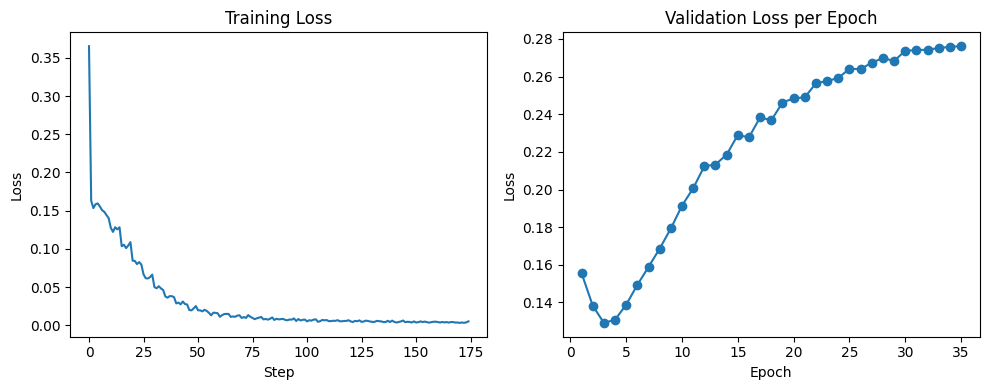

In [113]:
#Training and validation loss
logs = trainer.state.log_history
train_loss = [l["loss"] for l in logs if "loss" in l]
eval_loss = [l["eval_loss"] for l in logs if "eval_loss" in l]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.plot(train_loss); plt.title("Training Loss"); plt.xlabel("Step"); plt.ylabel("Loss")
plt.subplot(1, 2, 2); plt.plot(range(1, len(eval_loss) + 1), eval_loss, marker="o")
plt.title("Validation Loss per Epoch"); plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.tight_layout(); plt.show()

In [105]:
logging_strategy="steps",
logging_steps=50,
logging_first_step=True,
eval_strategy="epoch",
save_strategy="epoch",
load_best_model_at_end=True,

In [114]:
logs = trainer.state.log_history

print("Total logs:", len(logs))
print("Training losses:", sum("loss" in x and "eval_loss" not in x for x in logs))
print("Validation losses:", sum("eval_loss" in x for x in logs))

Total logs: 211
Training losses: 175
Validation losses: 35


In [115]:
print("Trainer type:", type(trainer))
print("Model:", type(trainer.model))
print("Training dataset size:", len(trainer.train_dataset))
print("Validation dataset size:", len(trainer.eval_dataset))

print("\nTraining arguments:")
print("Epochs:", trainer.args.num_train_epochs)
print("Logging strategy:", trainer.args.logging_strategy)
print("Logging steps:", trainer.args.logging_steps)
print("Evaluation strategy:", trainer.args.eval_strategy)

print("\nTraining state:")
print("Global step:", trainer.state.global_step)
print("Current epoch:", trainer.state.epoch)
print("Log history:", trainer.state.log_history)

Trainer type: <class 'transformers.trainer.Trainer'>
Model: <class 'transformers.models.distilbert.modeling_distilbert.DistilBertForSequenceClassification'>
Training dataset size: 4000
Validation dataset size: 800

Training arguments:
Epochs: 35
Logging strategy: IntervalStrategy.STEPS
Logging steps: 50
Evaluation strategy: IntervalStrategy.EPOCH

Training state:
Global step: 8750
Current epoch: 35.0
Log history: [{'loss': 0.36539852142333984, 'grad_norm': 0.40849027037620544, 'learning_rate': 4.972e-05, 'epoch': 0.2, 'step': 50}, {'loss': 0.16300434112548828, 'grad_norm': 0.2921622097492218, 'learning_rate': 4.9434285714285714e-05, 'epoch': 0.4, 'step': 100}, {'loss': 0.15337454795837402, 'grad_norm': 0.32170751690864563, 'learning_rate': 4.914857142857143e-05, 'epoch': 0.6, 'step': 150}, {'loss': 0.1584193515777588, 'grad_norm': 0.2789935767650604, 'learning_rate': 4.8862857142857146e-05, 'epoch': 0.8, 'step': 200}, {'loss': 0.159429874420166, 'grad_norm': 0.3245442807674408, 'learni

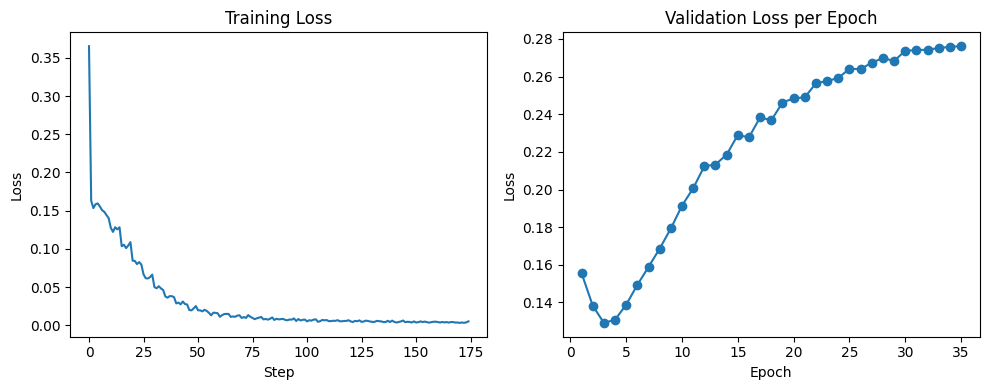

In [116]:
#Training and validation loss
logs = trainer.state.log_history
train_loss = [l["loss"] for l in logs if "loss" in l]
eval_loss = [l["eval_loss"] for l in logs if "eval_loss" in l]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.plot(train_loss); plt.title("Training Loss"); plt.xlabel("Step"); plt.ylabel("Loss")
plt.subplot(1, 2, 2); plt.plot(range(1, len(eval_loss) + 1), eval_loss, marker="o")
plt.title("Validation Loss per Epoch"); plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.tight_layout(); plt.show()

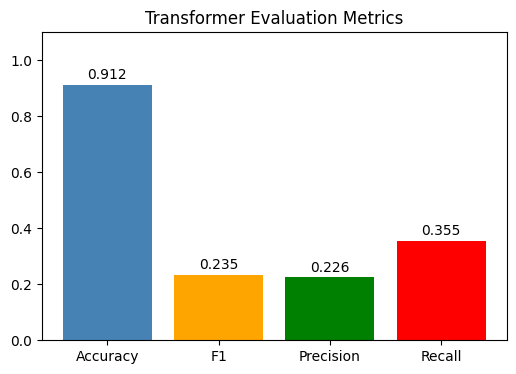

In [117]:
#Metrics bars
names = ["Accuracy", "F1", "Precision", "Recall"]
vals = [accuracy, f1, precision, recall]
plt.figure(figsize=(6, 4))
bars = plt.bar(names, vals, color=["steelblue", "orange", "green", "red"])
plt.ylim(0, 1.1); plt.title("Transformer Evaluation Metrics")
for b, v in zip(bars, vals):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center")
plt.show()

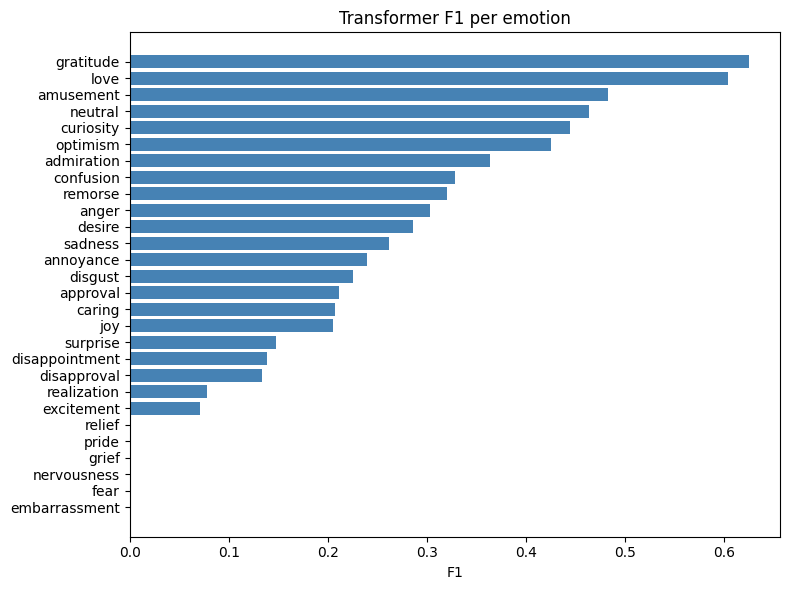

In [118]:
#Which emotions the Transformer finds hard
per_f1 = f1_score(true_labels, preds, average=None, zero_division=0)
order = np.argsort(per_f1)
plt.figure(figsize=(8, 6))
plt.barh([label_names[i] for i in order], per_f1[order], color="steelblue")
plt.xlabel("F1"); plt.title("Transformer F1 per emotion")
plt.tight_layout(); plt.show()

In [119]:
#Example
my_sentence = "I am so proud of what we achieved today!"
inputs = tokenizer(my_sentence, return_tensors="pt", truncation=True, padding=True, max_length=64)
inputs = {k: v.to(device) for k, v in inputs.items()}

model.eval()
with torch.no_grad():
    p = torch.sigmoid(model(**inputs).logits)[0].cpu().numpy()

for i in p.argsort()[-3:][::-1]:
    print(label_names[i], ":", round(float(p[i]), 3))

admiration : 0.328
joy : 0.138
approval : 0.128


In [120]:
my_sentence = "I am feeling very nervous today!"
inputs = tokenizer(my_sentence, return_tensors="pt", truncation=True, padding=True, max_length=64)
inputs = {k: v.to(device) for k, v in inputs.items()}

model.eval()
with torch.no_grad():
    p = torch.sigmoid(model(**inputs).logits)[0].cpu().numpy()

for i in p.argsort()[-3:][::-1]:
    print(label_names[i], ":", round(float(p[i]), 3))

sadness : 0.163
disappointment : 0.124
realization : 0.116


In [121]:
torch.save(model.state_dict(), f"{D}/transformer_model.pt")
tokenizer.save_pretrained(f"{D}/tokenizer_saved")
print("Transformer saved")

Transformer saved


In [122]:
torch.save(model.state_dict(), f"{D}/transformer_model.pt")
tokenizer.save_pretrained(f"{D}/tokenizer_saved")

('/content/drive/MyDrive/cognitive_mirror/tokenizer_saved/tokenizer_config.json',
 '/content/drive/MyDrive/cognitive_mirror/tokenizer_saved/tokenizer.json')

In [34]:
import os
D = "/content/drive/MyDrive/MyModels"
os.makedirs(D, exist_ok=True)

torch.save(model.state_dict(), f"{D}/transformer_model.pt")
tokenizer.save_pretrained(f"{D}/tokenizer_saved")

('/content/drive/MyDrive/MyModels/tokenizer_saved/tokenizer_config.json',
 '/content/drive/MyDrive/MyModels/tokenizer_saved/tokenizer.json')

In [2]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("device:", device)
for name in ["X_train_img", "X_val_img", "D"]:
    print(name, "OK" if name in globals() else "MISSING")

if "X_train_img" in globals() and "X_val_img" in globals():
    print(X_train_img.shape, X_val_img.shape)
else:
    print("Note: X_train_img or X_val_img variables are missing because their definition cells have not been executed yet.")

device: cuda
X_train_img MISSING
X_val_img MISSING
D MISSING
Note: X_train_img or X_val_img variables are missing because their definition cells have not been executed yet.


In [123]:
import os
from google.colab import drive
drive.mount('/content/drive')
D = "/content/drive/MyDrive/cognitive_mirror"
print(os.listdir(D))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['data.npz', 'transformer_model.pt', 'tokenizer_saved', 'ae_model.pt', 'vae_model.pt', 'transformer_model_backup.pt']


In [124]:
import numpy as np, torch
d = np.load(f"{D}/data.npz")
X_train_img = torch.tensor(d["train"]).to(device)
X_val_img = torch.tensor(d["val"]).to(device)
celeb_smile = np.concatenate([d["smile_train"], d["smile_val"]])
img_labels = celeb_smile                       # the later cells use this name
X_fer = torch.tensor(d["fer"]).to(device)
fer_labels = d["fer_labels"]
face_emotions = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]
split = len(X_train_img)
print(X_train_img.shape, X_val_img.shape, X_fer.shape)

torch.Size([18000, 2304]) torch.Size([2000, 2304]) torch.Size([6000, 2304])


In [7]:
for name in ["X_train_img", "X_val_img", "D", "img_labels", "split"]:
    print(name, "OK" if name in globals() else "MISSING")

X_train_img OK
X_val_img OK
D OK
img_labels OK
split OK


In [125]:
import json

required_vars = ["accuracy", "f1", "precision", "recall", "threshold", "label_names"]
missing = [var for var in required_vars if var not in globals()]

if not missing:
    metrics = {"accuracy": float(accuracy), "f1": float(f1),
               "precision": float(precision), "recall": float(recall),
               "threshold": float(threshold), "label_names": label_names}
    with open(f"{D}/metrics.json", "w") as f:
        json.dump(metrics, f)
    print("Saved Transformer scores")
else:
    print(f"Cannot save metrics yet. The following required variables are missing: {', '.join(missing)}.")
    print("Please run the evaluation cells (such as cell mizRZjRRc3Iq) first.")

Saved Transformer scores


In [126]:
#Build(AE)
import torch.nn.functional as F, copy
from torch.utils.data import DataLoader

LAT_AE = 256

def ssim_loss(x, y, win=7):
    x, y = x.view(-1, 1, 48, 48), y.view(-1, 1, 48, 48)
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    p = lambda t: F.avg_pool2d(t, win, 1, win // 2, count_include_pad=False)
    mx, my = p(x), p(y)
    sxx, syy, sxy = p(x * x) - mx ** 2, p(y * y) - my ** 2, p(x * y) - mx * my
    s = ((2 * mx * my + C1) * (2 * sxy + C2)) / ((mx ** 2 + my ** 2 + C1) * (sxx + syy + C2))
    return 1 - s.mean()

class ImageAE(nn.Module):
    def __init__(self, latent=LAT_AE):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Unflatten(1, (1, 48, 48)),
            nn.Conv2d(1, 32, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Flatten(), nn.Linear(256 * 3 * 3, latent))
        self.decoder = nn.Sequential(
            nn.Linear(latent, 256 * 3 * 3), nn.ReLU(), nn.Unflatten(1, (256, 3, 3)),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid(), nn.Flatten())
    def forward(self, x):
        return self.decoder(self.encoder(x))

img_ae = ImageAE().to(device)
img_ae_opt = optim.Adam(img_ae.parameters(), lr=0.0005)
mse = nn.MSELoss()
train_loader = DataLoader(X_train_img, batch_size=128, shuffle=True)

img_ae_losses, img_ae_val_losses = [], []
best_val, best_state, wait, PATIENCE = 1e9, None, 0, 10

for epoch in range(100):
    img_ae.train()
    total = 0
    for batch in train_loader:
        img_ae_opt.zero_grad()
        out = img_ae(batch)
        loss = mse(out, batch) + 0.5 * F.l1_loss(out, batch) + 0.5 * ssim_loss(out, batch)
        loss.backward()
        img_ae_opt.step()
        total += mse(out, batch).item()
    img_ae_losses.append(total / len(train_loader))

    img_ae.eval()
    with torch.no_grad():
        val = mse(img_ae(X_val_img), X_val_img).item()
    img_ae_val_losses.append(val)

    if val < best_val - 1e-6:
        best_val, best_state, wait = val, copy.deepcopy(img_ae.state_dict()), 0
    else:
        wait += 1
        if wait >= PATIENCE:
            print("Stopped early at epoch", epoch)
            break
    if epoch % 10 == 0:
        print("Epoch", epoch, "Train:", round(img_ae_losses[-1], 5), "Val:", round(val, 5))

img_ae.load_state_dict(best_state)
torch.save(img_ae.state_dict(), f"{D}/ae_model.pt")
print("AE saved. Best validation recon:", round(best_val, 5))

Epoch 0 Train: 0.04734 Val: 0.02127
Epoch 10 Train: 0.00604 Val: 0.00603
Epoch 20 Train: 0.00437 Val: 0.00446
Epoch 30 Train: 0.00368 Val: 0.00394
Epoch 40 Train: 0.00329 Val: 0.00362
Epoch 50 Train: 0.00303 Val: 0.00332
Epoch 60 Train: 0.0028 Val: 0.00316
Epoch 70 Train: 0.00263 Val: 0.00305
Epoch 80 Train: 0.00253 Val: 0.00294
Epoch 90 Train: 0.00242 Val: 0.00293
AE saved. Best validation recon: 0.00282


In [127]:
img_ae.eval()
with torch.no_grad():
    o = img_ae(X_val_img[:4])
print("difference between outputs:", (o[0] - o[1]).abs().mean().item())
print("val MSE:", mse(img_ae(X_val_img), X_val_img).item())

difference between outputs: 0.459051251411438
val MSE: 0.0028229777235537767


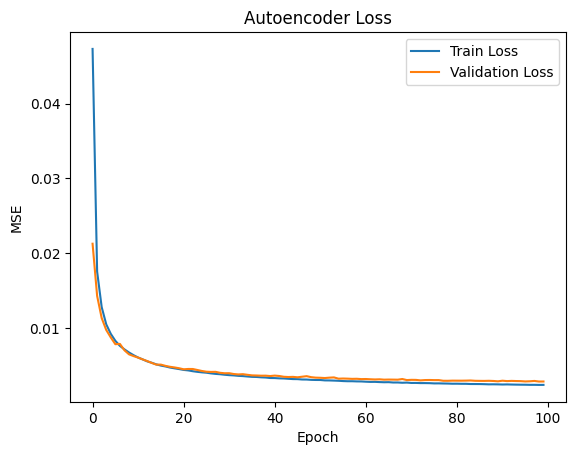

In [128]:
#Loss curve
plt.plot(img_ae_losses, label="Train Loss")
plt.plot(img_ae_val_losses, label="Validation Loss")
plt.title("Autoencoder Loss"); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

In [129]:
#MSE, PSNR and SSIM
img_ae.eval()
with torch.no_grad():
    recon_val = img_ae(X_val_img)

ae_mse = mse(recon_val, X_val_img).item()
ae_psnr = 10 * np.log10(1.0 / ae_mse)
orig_np = X_val_img.cpu().numpy()
recon_np = recon_val.cpu().numpy()
ae_ssim = np.mean([ssim(orig_np[i].reshape(48, 48), recon_np[i].reshape(48, 48), data_range=1.0) for i in range(200)])

print("AE MSE:", ae_mse)
print("AE PSNR:", ae_psnr)
print("AE SSIM:", ae_ssim)

AE MSE: 0.0028229777235537767
AE PSNR: 25.49292548907931
AE SSIM: 0.8892504524219101


In [130]:
print("epochs trained:", len(img_ae_losses))
print("last train loss:", img_ae_losses[-1] if img_ae_losses else "never trained")

epochs trained: 100
last train loss: 0.0023739579734755748


best val MSE: 0.00282 | epochs run: 100
difference between faces: 0.459051251411438


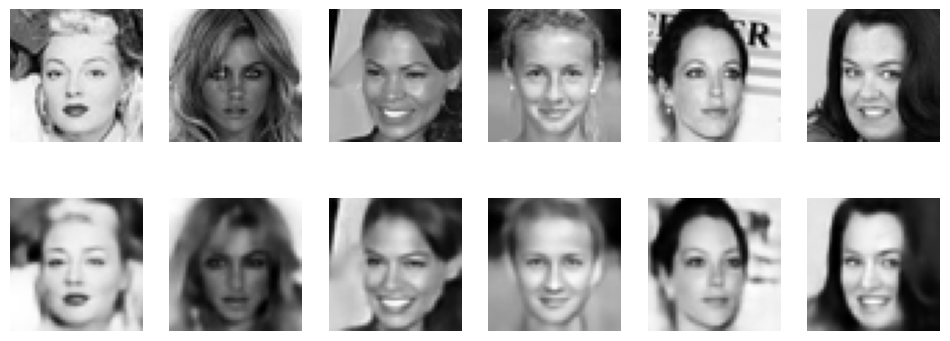

In [131]:

#Original vs rebuilt faces
img_ae.eval()
with torch.no_grad():
    o = img_ae(X_val_img[:6])
print("best val MSE:", round(best_val, 5), "| epochs run:", len(img_ae_losses))
print("difference between faces:", (o[0] - o[1]).abs().mean().item())

fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for i in range(6):
    axes[0][i].imshow(X_val_img[i].cpu().numpy().reshape(48, 48), cmap="gray"); axes[0][i].axis("off")
    axes[1][i].imshow(o[i].cpu().numpy().reshape(48, 48), cmap="gray"); axes[1][i].axis("off")
plt.show()

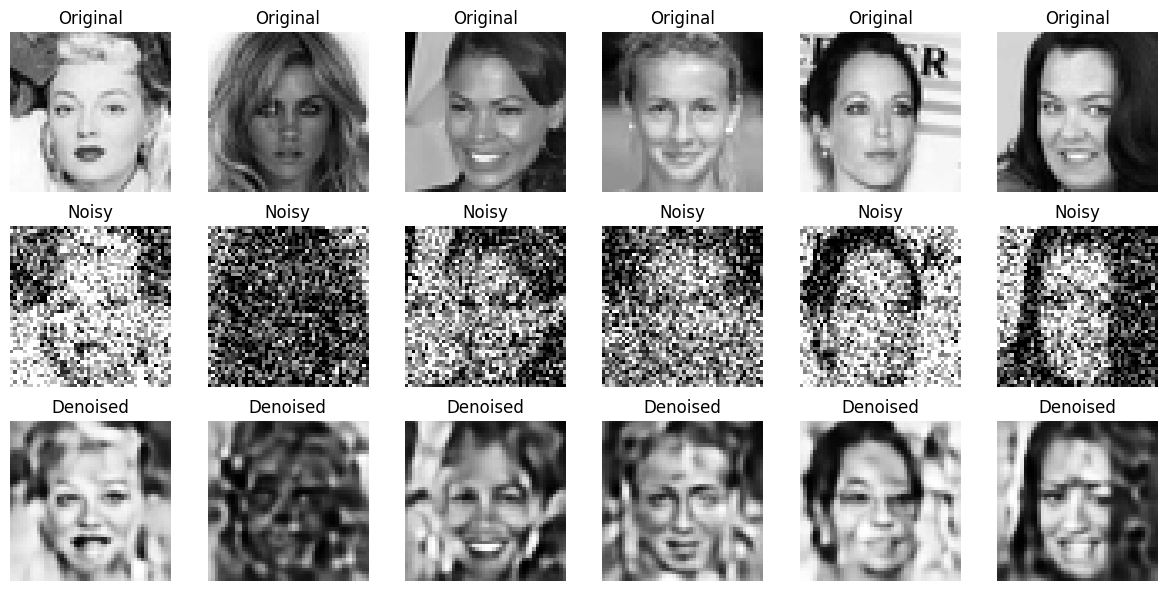

In [132]:
#Denoising demo
noisy = torch.clamp(X_val_img[:6] + torch.randn_like(X_val_img[:6]) * 0.3, 0, 1)
with torch.no_grad():
    cleaned = img_ae(noisy)

fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for i in range(6):
    axes[0][i].imshow(X_val_img[i].cpu().numpy().reshape(48, 48), cmap="gray"); axes[0][i].set_title("Original")
    axes[1][i].imshow(noisy[i].cpu().numpy().reshape(48, 48), cmap="gray"); axes[1][i].set_title("Noisy")
    axes[2][i].imshow(cleaned[i].cpu().numpy().reshape(48, 48), cmap="gray"); axes[2][i].set_title("Denoised")
    for r in range(3):
        axes[r][i].axis("off")
plt.tight_layout(); plt.show()

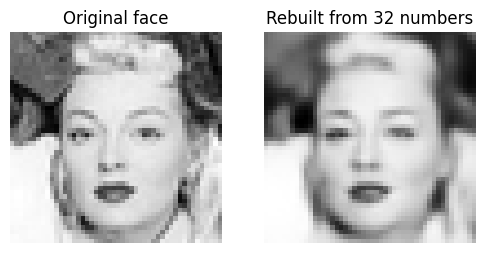

In [133]:

#Privacy test (32 numbers rebuild the face)
face = X_val_img[0:1]
with torch.no_grad():
    rebuilt = img_ae.decoder(img_ae.encoder(face))

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(face.cpu().numpy().reshape(48, 48), cmap="gray"); axes[0].set_title("Original face")
axes[1].imshow(rebuilt.cpu().numpy().reshape(48, 48), cmap="gray"); axes[1].set_title("Rebuilt from 32 numbers")
for a in axes:
    a.axis("off")
plt.show()

In [134]:
metrics = {"accuracy": float(accuracy), "f1": float(f1),
           "precision": float(precision), "recall": float(recall),
           "threshold": float(threshold), "label_names": label_names}
with open(f"{D}/metrics.json", "w") as f:
    json.dump(metrics, f)
print("Transformer scores saved:", metrics["f1"])

Transformer scores saved: 0.23453678101535333


In [135]:
#build VAE
class ImageVAE(nn.Module):
    def __init__(self, latent=32):
        super().__init__()
        self.hidden = nn.Sequential(
            nn.Unflatten(1, (1, 48, 48)),
            nn.Conv2d(1, 32, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(32, 64, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 4, 2, 1), nn.LeakyReLU(0.2),
            nn.Flatten())
        self.mean_layer = nn.Linear(256 * 3 * 3, latent)
        self.logvar_layer = nn.Linear(256 * 3 * 3, latent)
        self.decoder = nn.Sequential(
            nn.Linear(latent, 256 * 3 * 3), nn.ReLU(), nn.Unflatten(1, (256, 3, 3)),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid(), nn.Flatten())
    def forward(self, x):
        h = self.hidden(x)
        mean = self.mean_layer(h)
        logvar = self.logvar_layer(h)
        z = mean + torch.randn_like(mean) * torch.exp(0.5 * logvar)
        return self.decoder(z), mean, logvar

img_vae = ImageVAE().to(device)
img_vae_opt = optim.Adam(img_vae.parameters(), lr=0.0005)
BETA, WARMUP = 0.5, 10      # BETA: higher = smoother random faces but blurrier rebuilds

vae_recon_losses, vae_kl_losses, vae_val_losses = [], [], []
best_val_vae, best_state_vae = 1e9, None

for epoch in range(100):
    img_vae.train()
    warm = min(1.0, epoch / WARMUP)
    r_total, k_total = 0, 0
    for batch in train_loader:
        img_vae_opt.zero_grad()
        out, mean, logvar = img_vae(batch)
        recon_loss = F.mse_loss(out, batch)
        recon_all = recon_loss + 0.5 * F.l1_loss(out, batch) + 0.5 * ssim_loss(out, batch)
        kl_ps = -0.5 * torch.sum(1 + logvar - mean.pow(2) - logvar.exp(), dim=1).mean() / 2304
        loss = recon_all + BETA * warm * kl_ps
        loss.backward()
        img_vae_opt.step()
        r_total += recon_loss.item()
        k_total += (-0.5 * torch.mean(1 + logvar - mean.pow(2) - logvar.exp())).item()
    vae_recon_losses.append(r_total / len(train_loader))
    vae_kl_losses.append(k_total / len(train_loader))

    img_vae.eval()
    with torch.no_grad():
        v_out, _, _ = img_vae(X_val_img)
        val_v = F.mse_loss(v_out, X_val_img).item()
    vae_val_losses.append(val_v)
    if val_v < best_val_vae:
        best_val_vae, best_state_vae = val_v, copy.deepcopy(img_vae.state_dict())

    if epoch % 10 == 0:
        print("Epoch", epoch, "Recon:", round(vae_recon_losses[-1], 5), "KL:", round(vae_kl_losses[-1], 4), "Val:", round(val_v, 5))

img_vae.load_state_dict(best_state_vae)
torch.save(img_vae.state_dict(), f"{D}/vae_model.pt")
print("VAE saved. Best validation recon:", round(best_val_vae, 5))

Epoch 0 Recon: 0.0441 KL: 10.0993 Val: 0.02175
Epoch 10 Recon: 0.01029 KL: 2.3972 Val: 0.01039
Epoch 20 Recon: 0.00944 KL: 2.439 Val: 0.00998
Epoch 30 Recon: 0.009 KL: 2.4765 Val: 0.01008
Epoch 40 Recon: 0.00865 KL: 2.5194 Val: 0.01022
Epoch 50 Recon: 0.00836 KL: 2.5553 Val: 0.0103
Epoch 60 Recon: 0.00815 KL: 2.5811 Val: 0.01041
Epoch 70 Recon: 0.00795 KL: 2.6111 Val: 0.01042
Epoch 80 Recon: 0.00779 KL: 2.6316 Val: 0.01063
Epoch 90 Recon: 0.00768 KL: 2.6526 Val: 0.01076
VAE saved. Best validation recon: 0.00998


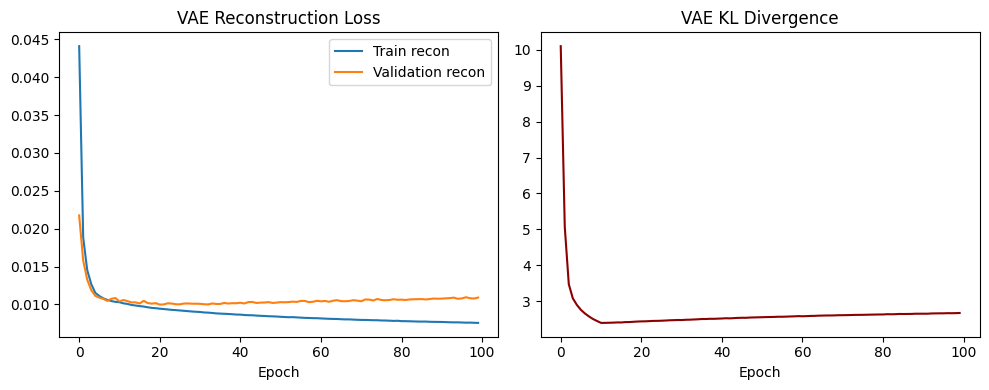

In [136]:
#N1.2 VAE: metrics and charts
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(vae_recon_losses, label="Train recon"); plt.plot(vae_val_losses, label="Validation recon")
plt.title("VAE Reconstruction Loss"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(vae_kl_losses, color="darkred"); plt.title("VAE KL Divergence"); plt.xlabel("Epoch")
plt.tight_layout(); plt.show()

In [137]:
#MSE,PSNR
img_vae.eval()
with torch.no_grad():
    vae_out, v_mean, v_logvar = img_vae(X_val_img)

vae_mse = mse(vae_out, X_val_img).item()
vae_psnr = 10 * np.log10(1.0 / vae_mse)
vae_kl = (-0.5 * torch.mean(1 + v_logvar - v_mean.pow(2) - v_logvar.exp())).item()
vae_np = vae_out.cpu().numpy()
orig_np = X_val_img.cpu().numpy()
vae_ssim = np.mean([ssim(orig_np[i].reshape(48, 48), vae_np[i].reshape(48, 48), data_range=1.0) for i in range(200)])

print("VAE MSE:", vae_mse)
print("VAE KL:", vae_kl)
print("VAE PSNR:", vae_psnr)
print("VAE SSIM:", vae_ssim)

VAE MSE: 0.00998698640614748
VAE KL: 2.4822945594787598
VAE PSNR: 20.00565541266071
VAE SSIM: 0.6815743328397796


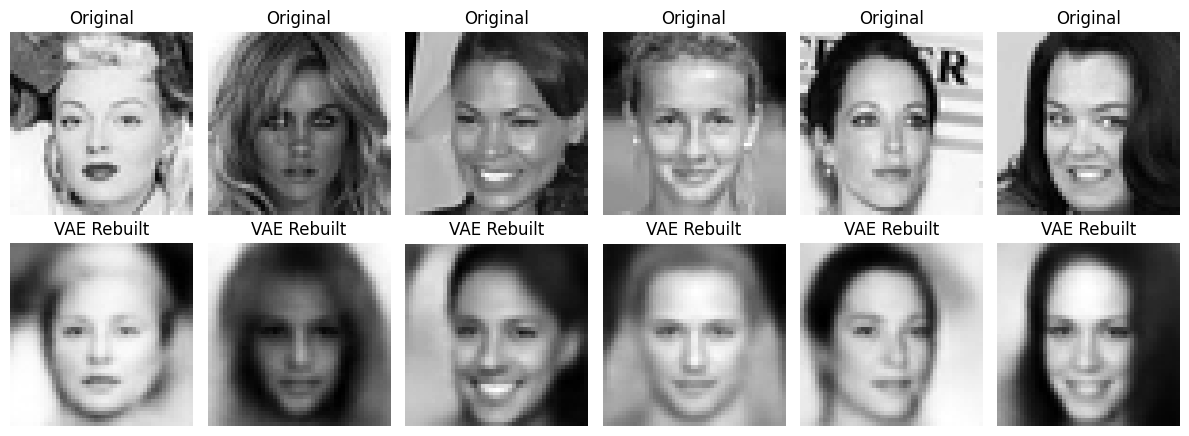

In [138]:
#Original vs VAE rebuilt
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for i in range(6):
    axes[0][i].imshow(orig_np[i].reshape(48, 48), cmap="gray"); axes[0][i].set_title("Original")
    axes[1][i].imshow(vae_np[i].reshape(48, 48), cmap="gray"); axes[1][i].set_title("VAE Rebuilt")
    axes[0][i].axis("off"); axes[1][i].axis("off")
plt.tight_layout(); plt.show()

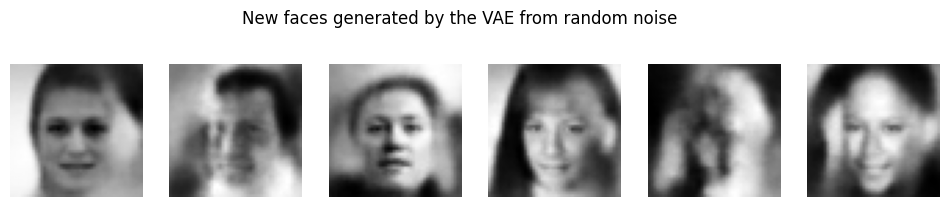

In [139]:
#Brand new faces from random noise
with torch.no_grad():
    new_faces = img_vae.decoder(torch.randn(6, 32).to(device)).cpu().numpy()

fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for i in range(6):
    axes[i].imshow(new_faces[i].reshape(48, 48), cmap="gray"); axes[i].axis("off")
plt.suptitle("New faces generated by the VAE from random noise")
plt.show()

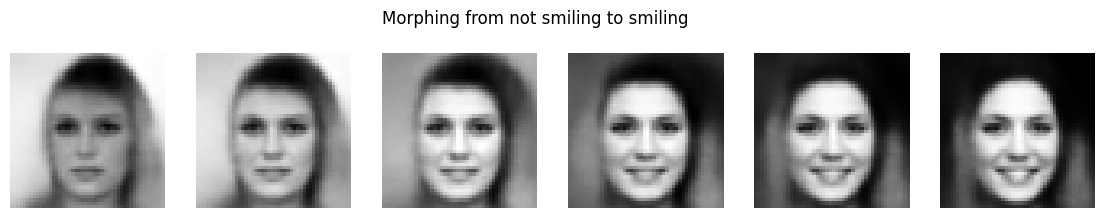

In [140]:
#Smile morphing (CelebA smiling labels: 0 = not smiling, 1 = smiling)
not_i = np.where(img_labels[:split] == 0)[0][0]
smile_i = np.where(img_labels[:split] == 1)[0][0]

with torch.no_grad():
    m1 = img_vae.mean_layer(img_vae.hidden(X_train_img[not_i:not_i+1]))
    m2 = img_vae.mean_layer(img_vae.hidden(X_train_img[smile_i:smile_i+1]))

fig, axes = plt.subplots(1, 6, figsize=(14, 2.5))
for i, a in enumerate(np.linspace(0, 1, 6)):
    with torch.no_grad():
        axes[i].imshow(img_vae.decoder((1 - a) * m1 + a * m2).cpu().numpy().reshape(48, 48), cmap="gray")
    axes[i].axis("off")
plt.suptitle("Morphing from not smiling to smiling")
plt.show()

In [141]:
img_ae.eval()
with torch.no_grad():
    recon_val = img_ae(X_val_img)
ae_mse = mse(recon_val, X_val_img).item()
ae_psnr = 10 * np.log10(1.0 / ae_mse)
recon_np = recon_val.cpu().numpy()
ae_ssim = np.mean([ssim(orig_np[i].reshape(48, 48), recon_np[i].reshape(48, 48), data_range=1.0) for i in range(200)])
print("AE:", ae_mse, ae_psnr, ae_ssim)

AE: 0.0028229777235537767 25.49292548907931 0.8892504560879977


In [143]:
m = json.load(open(f"{D}/metrics.json"))
accuracy, f1, precision, recall = m["accuracy"], m["f1"], m["precision"], m["recall"]
label_names = m["label_names"]
print(accuracy, f1, precision, recall)

0.9117857142857143 0.23453678101535333 0.22563746978596702 0.3546578818886328


In [147]:
#Comparison of the first three models
import json
import os

metrics_path = f"{D}/metrics.json"

if os.path.exists(metrics_path):
    with open(metrics_path, "r") as f:
        m = json.load(f)
    accuracy = m.get("accuracy")
    f1 = m.get("f1")
    precision = m.get("precision")
    recall = m.get("recall")
    label_names = m.get("label_names")
    print("Metrics loaded successfully:")
    print("Accuracy:", accuracy,)
    print("F1:", f1,)
    print("Precision:", precision,)
    print("Recall:", recall)
else:
    print(f"Error: '{metrics_path}' not found.")
    print("Please make sure you have run the evaluation cell (mizRZjRRc3Iq) and the save cell (5msAbWSbGh4E) first.")

Metrics loaded successfully:
Accuracy: 0.9117857142857143
F1: 0.23453678101535333
Precision: 0.22563746978596702
Recall: 0.3546578818886328


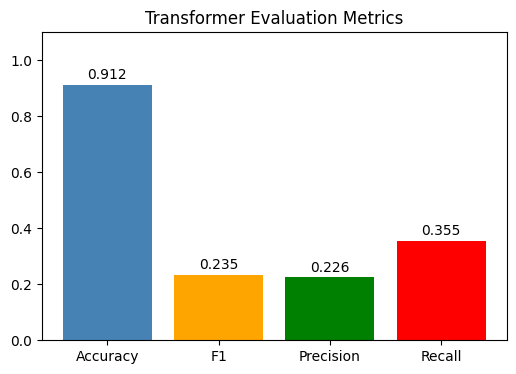

In [148]:
#Transformer metrics chart
names = ["Accuracy", "F1", "Precision", "Recall"]
vals = [accuracy, f1, precision, recall]
plt.figure(figsize=(6, 4))
bars = plt.bar(names, vals, color=["steelblue", "orange", "green", "red"])
plt.ylim(0, 1.1); plt.title("Transformer Evaluation Metrics")
for b, v in zip(bars, vals):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center")
plt.show()

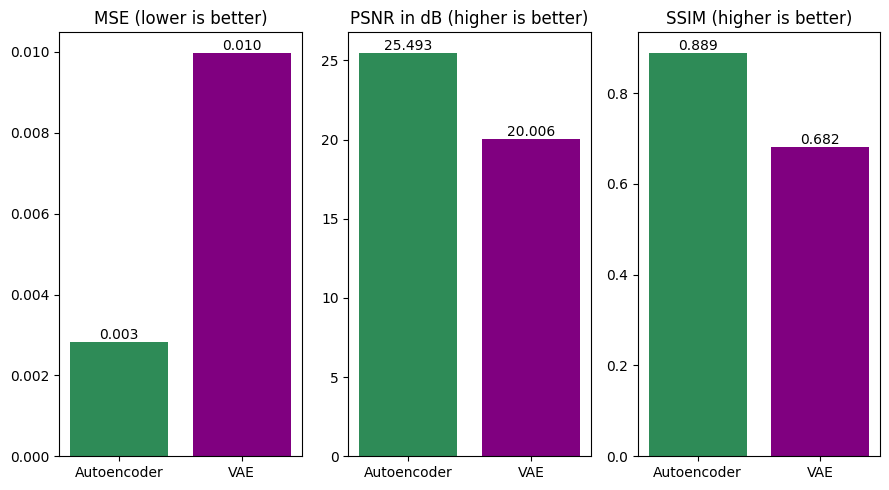

In [153]:
#AE vs VAE chart
fig, axes = plt.subplots(1, 3, figsize=(9, 5))
axes[0].bar(["Autoencoder", "VAE"], [ae_mse, vae_mse], color=["seagreen", "purple"]); axes[0].set_title("MSE (lower is better)")
axes[1].bar(["Autoencoder", "VAE"], [ae_psnr, vae_psnr], color=["seagreen", "purple"]); axes[1].set_title("PSNR in dB (higher is better)")
axes[2].bar(["Autoencoder", "VAE"], [ae_ssim, vae_ssim], color=["seagreen", "purple"]); axes[2].set_title("SSIM (higher is better)")
for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=10)
plt.tight_layout(); plt.show()

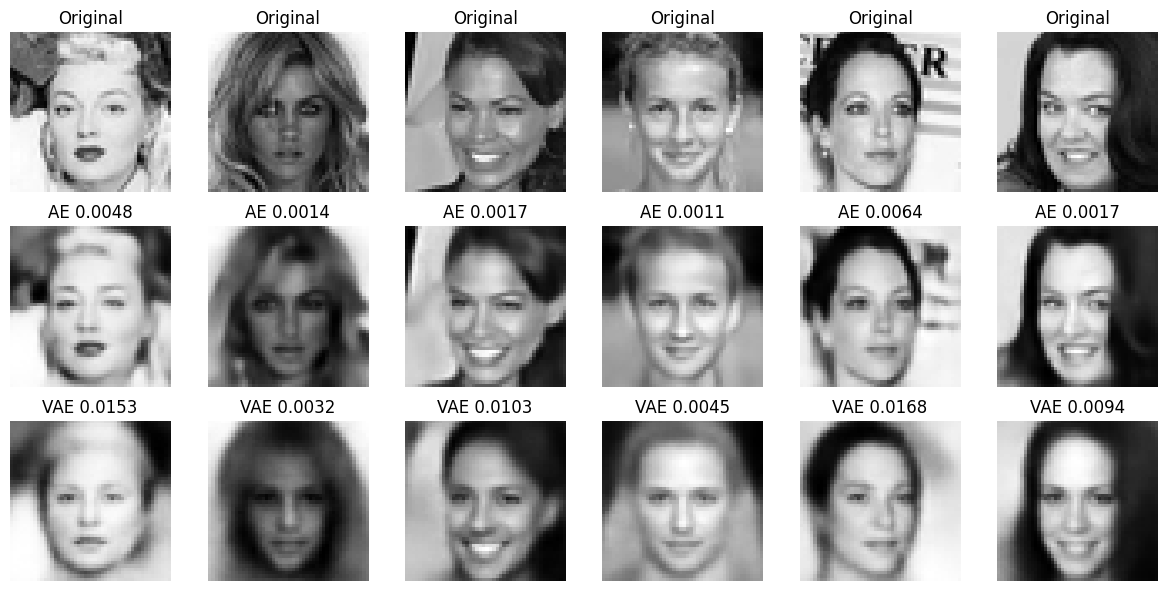

In [154]:
#Same faces through the AE and the VAE
fig, axes = plt.subplots(3, 6, figsize=(12, 6))
for i in range(6):
    ae_err = np.mean((orig_np[i] - recon_np[i]) ** 2)
    vae_err = np.mean((orig_np[i] - vae_np[i]) ** 2)
    axes[0][i].imshow(orig_np[i].reshape(48, 48), cmap="gray"); axes[0][i].set_title("Original")
    axes[1][i].imshow(recon_np[i].reshape(48, 48), cmap="gray"); axes[1][i].set_title(f"AE {ae_err:.4f}")
    axes[2][i].imshow(vae_np[i].reshape(48, 48), cmap="gray"); axes[2][i].set_title(f"VAE {vae_err:.4f}")
    for r in range(3):
        axes[r][i].axis("off")
plt.tight_layout(); plt.show()

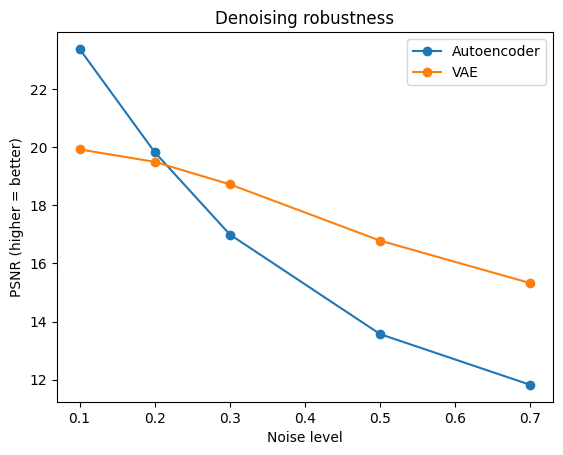

In [155]:
#Noise robustness, AE vs VAE
levels = [0.1, 0.2, 0.3, 0.5, 0.7]
ae_p, vae_p = [], []
for lv in levels:
    noisy = torch.clamp(X_val_img + torch.randn_like(X_val_img) * lv, 0, 1)
    with torch.no_grad():
        a = img_ae(noisy)
        v, _, _ = img_vae(noisy)
    ae_p.append(10 * np.log10(1 / mse(a, X_val_img).item()))
    vae_p.append(10 * np.log10(1 / mse(v, X_val_img).item()))

plt.plot(levels, ae_p, marker="o", label="Autoencoder")
plt.plot(levels, vae_p, marker="o", label="VAE")
plt.xlabel("Noise level"); plt.ylabel("PSNR (higher = better)")
plt.title("Denoising robustness"); plt.legend(); plt.show()

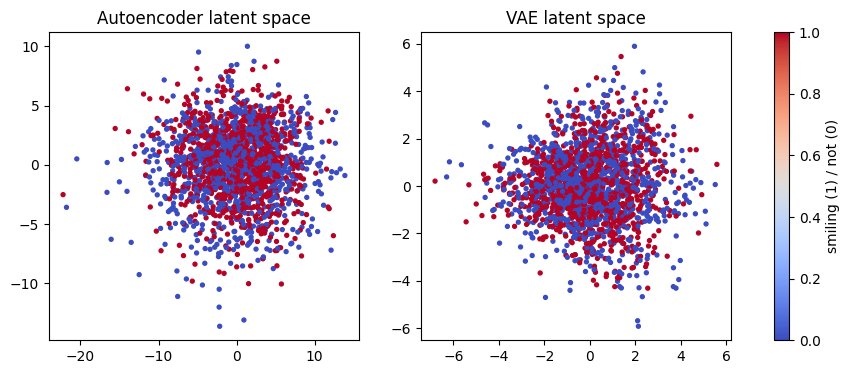

In [156]:
#Latent space, AE vs VAE (coloured by smiling or not)
from sklearn.decomposition import PCA

with torch.no_grad():
    ae_z = img_ae.encoder(X_val_img).cpu().numpy()
    vae_z = img_vae.mean_layer(img_vae.hidden(X_val_img)).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, z, t in [(axes[0], ae_z, "Autoencoder latent space"), (axes[1], vae_z, "VAE latent space")]:
    p = PCA(n_components=2).fit_transform(z)
    sc = ax.scatter(p[:, 0], p[:, 1], c=img_labels[split:], cmap="coolwarm", s=8)
    ax.set_title(t)
plt.colorbar(sc, ax=axes, label="smiling (1) / not (0)")
plt.show()

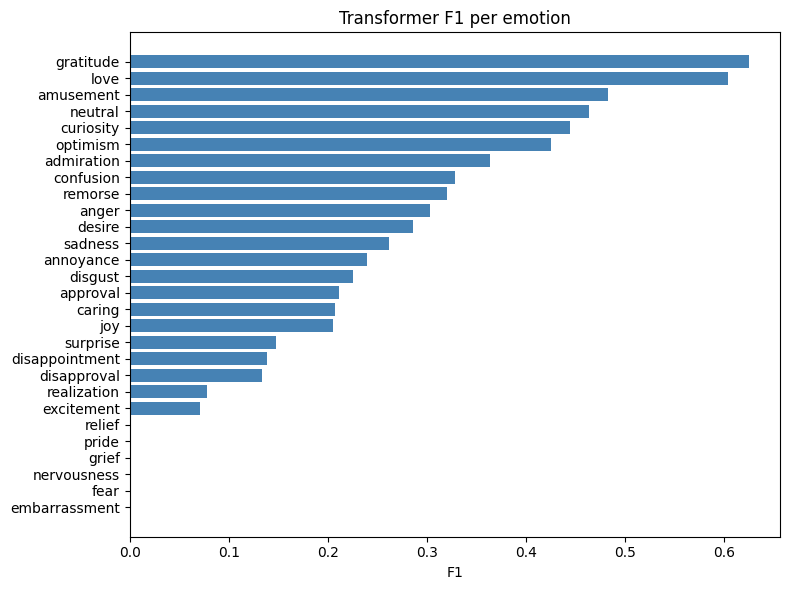

In [158]:
#transformer finds hard
from sklearn.metrics import f1_score
per_f1 = f1_score(true_labels, preds, average=None, zero_division=0)
order = np.argsort(per_f1)
plt.figure(figsize=(8, 6))
plt.barh([label_names[i] for i in order], per_f1[order], color="steelblue")
plt.xlabel("F1"); plt.title("Transformer F1 per emotion")
plt.tight_layout(); plt.show()

In [159]:
print("Higher PSNR:", "Autoencoder" if ae_psnr > vae_psnr else "VAE")
print("Higher SSIM:", "Autoencoder" if ae_ssim > vae_ssim else "VAE")
print("Only the VAE can generate new faces and morph between expressions.")

Higher PSNR: Autoencoder
Higher SSIM: Autoencoder
Only the VAE can generate new faces and morph between expressions.


In [160]:
metrics = json.load(open(f"{D}/metrics.json")) if os.path.exists(f"{D}/metrics.json") else {}
metrics.update({
    "accuracy": float(accuracy), "f1": float(f1), "precision": float(precision), "recall": float(recall),
    "ae_mse": float(ae_mse), "ae_psnr": float(ae_psnr), "ae_ssim": float(ae_ssim),
    "vae_mse": float(vae_mse), "vae_psnr": float(vae_psnr), "vae_ssim": float(vae_ssim), "vae_kl": float(vae_kl),
    "label_names": label_names, "lat_ae": int(LAT_AE)})
json.dump(metrics, open(f"{D}/metrics.json", "w"))
print(sorted(os.listdir(D)))

['ae_model.pt', 'data.npz', 'metrics.json', 'tokenizer_saved', 'transformer_model.pt', 'transformer_model_backup.pt', 'vae_model.pt']


In [161]:
import os, json
from google.colab import drive
drive.mount('/content/drive')
D = "/content/drive/MyDrive/cognitive_mirror"
os.makedirs(D, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [162]:
import os, json
from google.colab import drive
drive.mount('/content/drive')
D = "/content/drive/MyDrive/cognitive_mirror"
os.makedirs(D, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [163]:
torch.save(model.state_dict(), f"{D}/transformer_model.pt")
tokenizer.save_pretrained(f"{D}/tokenizer_saved")
torch.save(img_ae.state_dict(), f"{D}/ae_model.pt")
torch.save(img_vae.state_dict(), f"{D}/vae_model.pt")
print("Models saved to", D)

Models saved to /content/drive/MyDrive/cognitive_mirror
